In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

train = pd.read_csv("../data/processed/train_FD001_processed.csv")
test  = pd.read_csv("../data/processed/test_FD001_processed.csv")
print(train.shape, test.shape)

(20631, 20) (13096, 19)


In [13]:
RUL_CAP = 125
train["RUL_capped"] = train["RUL"].clip(upper=RUL_CAP)

FEATURES = ["op_setting_1", "op_setting_2",
            "sensor_2", "sensor_3", "sensor_4", "sensor_7", "sensor_8", "sensor_9",
            "sensor_11", "sensor_12", "sensor_13", "sensor_14", "sensor_15",
            "sensor_17", "sensor_20", "sensor_21"]

X = train[FEATURES]
y = train["RUL_capped"]
groups = train["engine_id"]

In [14]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(splitter.split(X, y, groups))

X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]
print(groups.iloc[train_idx].nunique(), groups.iloc[val_idx].nunique())   # 80 and 20

80 20


In [15]:
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)

pred_val = rf.predict(X_val)
print("MAE :", mean_absolute_error(y_val, pred_val))
print("RMSE:", np.sqrt(mean_squared_error(y_val, pred_val)))
print("R2  :", r2_score(y_val, pred_val))

MAE : 12.408378841144431
RMSE: 17.062720033454042
R2  : 0.8326990799216278


In [16]:
# train on ALL training engines for the final model
rf_final = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1)
rf_final.fit(X, y)

# NASA gives true RUL only for the LAST cycle of each test engine
last_rows = test.loc[test.groupby("engine_id")["cycle"].idxmax()].reset_index(drop=True)
true_rul = pd.read_csv("../data/raw/RUL_FD001.txt", header=None, sep=r"\s+")[0].clip(upper=RUL_CAP)

pred_test = rf_final.predict(last_rows[FEATURES])

test_mae  = mean_absolute_error(true_rul, pred_test)
test_rmse = np.sqrt(mean_squared_error(true_rul, pred_test))
test_r2   = r2_score(true_rul, pred_test)
print(test_mae, test_rmse, test_r2)

12.050549501817624 16.944437343426465 0.8212094354700463


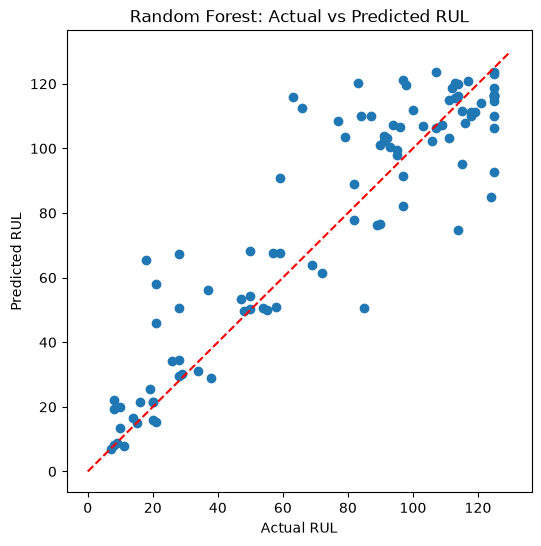

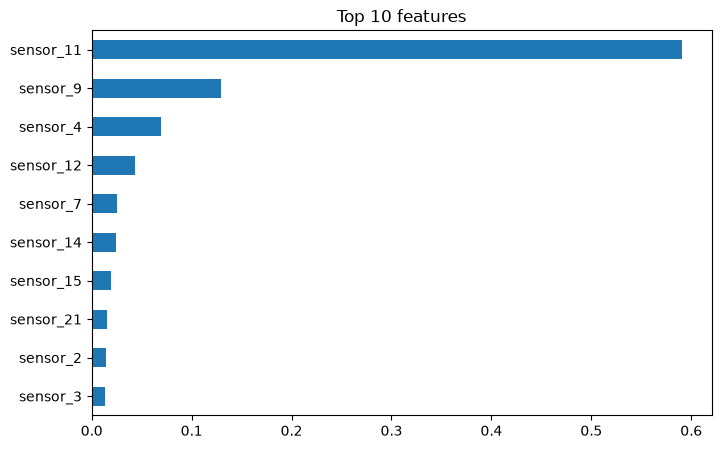

In [17]:
# actual vs predicted
plt.figure(figsize=(6, 6))
plt.scatter(true_rul, pred_test)
plt.plot([0, 130], [0, 130], "r--")
plt.xlabel("Actual RUL"); plt.ylabel("Predicted RUL")
plt.title("Random Forest: Actual vs Predicted RUL")
plt.savefig("../results/figures/rf_actual_vs_predicted.png", dpi=150)
plt.show()

# feature importance
imp = pd.Series(rf_final.feature_importances_, index=FEATURES).sort_values()
imp.tail(10).plot(kind="barh", figsize=(8, 5), title="Top 10 features")
plt.savefig("../results/figures/rf_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
joblib.dump(rf_final, "../models/random_forest.pkl", compress=3)

pd.DataFrame([{"model": "Random Forest", "split": "test (true RUL capped at 125)",
               "MAE": test_mae, "RMSE": test_rmse, "R2": test_r2}]
            ).to_csv("../results/metrics/rf_metrics.csv", index=False)

In [20]:
import sys
sys.path.append("../src")
from prediction import load_model, predict_rul, get_status

model = load_model()
engine_24 = test[test["engine_id"] == 24]
preds = predict_rul(model, engine_24)

print(preds[-1], get_status(preds[-1]))

21.559876151626145 Warning
